In [1]:
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats
import numpy as np



from google.colab import drive
drive.mount('/content/gdrive')

attendance_df = pd.read_csv(r'/content/gdrive/My Drive/ECON 692/WNBA All Game Attendance - All Game Attendance.csv')

Mounted at /content/gdrive


In [2]:
# Convert Year, Month, and Day into a proper Date column
attendance_df["Date"] = pd.to_datetime(attendance_df[["Year", "Month", "Day"]].astype(str).agg('-'.join, axis=1), errors='coerce')

In [3]:
attendance_df.head()

,Unnamed: 0,Year,Day of Week,Month,Day,Time (ET),Game Type,Home Team,Away Team,Arena,City,State,Attendance,Date
0,1,1997,Saturday,June,21,4:00 PM,Regular season,Los Angeles Sparks,New York Liberty,Great Western Forum,Los Angeles,CA,14284,1997-06-21
1,2,1997,Saturday,June,21,7:00 PM,Regular season,Cleveland Rockers,Houston Comets,Quicken Loans Arena,Cleveland,OH,11455,1997-06-21
2,3,1997,Saturday,June,21,5:00 AM,Regular season,Utah Starzz,Sacramento Monarchs,EnergySolutions Arena,Salt Lake City,UT,8915,1997-06-21
3,4,1997,Sunday,June,22,4:00 PM,Regular season,Phoenix Mercury,Charlotte Sting,US Airways Center,Phoenix,AZ,16102,1997-06-22
4,5,1997,Monday,June,23,3:00 AM,Regular season,Utah Starzz,Los Angeles Sparks,EnergySolutions Arena,Salt Lake City,UT,8036,1997-06-23


/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-4-b927564e3095>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


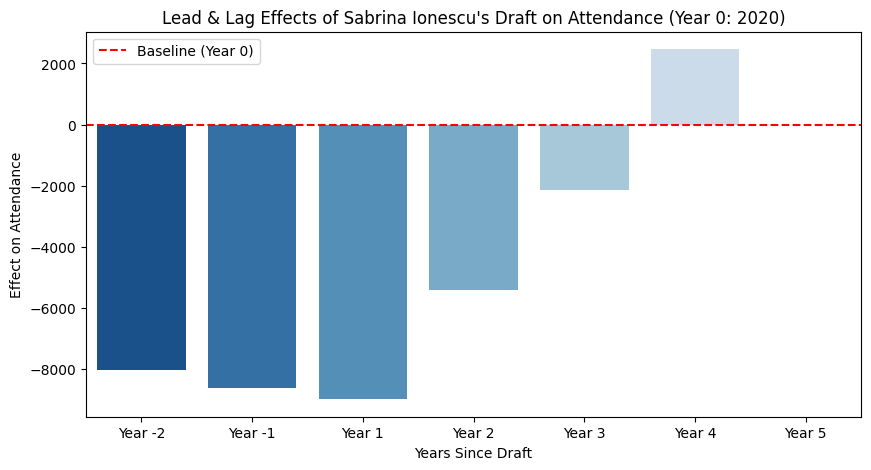

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-4-b927564e3095>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


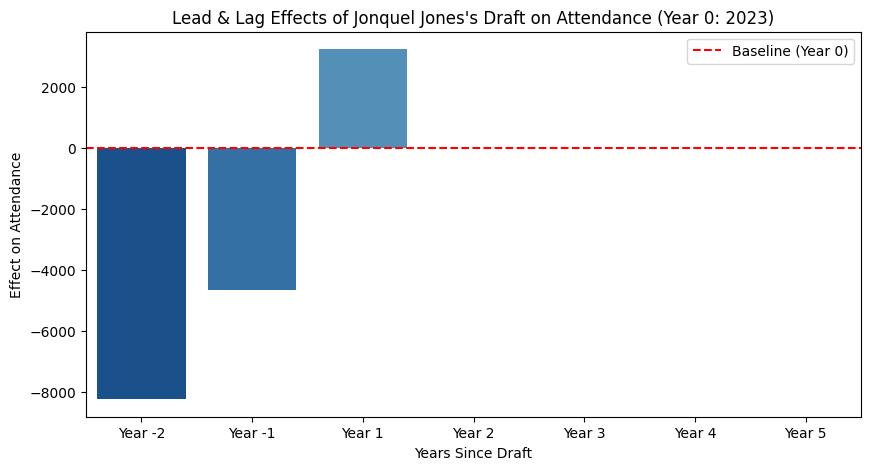

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-4-b927564e3095>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


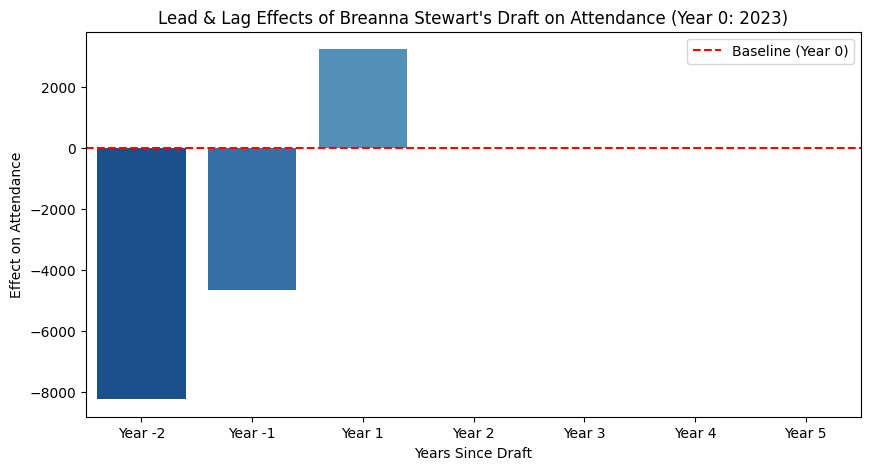

Regression Results for Sabrina Ionescu (Year Acquired: 2020):
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.421
Model:                            OLS   Adj. R-squared:                  0.414
Method:                 Least Squares   F-statistic:                     60.06
Date:                Wed, 30 Apr 2025   Prob (F-statistic):           8.45e-56
Time:                        04:46:10   Log-Likelihood:                -4783.6
No. Observations:                 503   AIC:                             9581.
Df Residuals:                     496   BIC:                             9611.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

In [4]:
# New York Liberty Games
ny_liberty_games = attendance_df[attendance_df["Home Team"] == "New York Liberty"].copy()

# Define Draft, Trade, and Free Agency Years
draft_trade_free_agency_dates = {
    "Sabrina Ionescu": pd.Timestamp("2020-04-17"), # drafted
    "Jonquel Jones": pd.Timestamp("2023-01-16"), # traded
    "Breanna Stewart": pd.Timestamp("2023-02-01") # free agency
}

# Loop through each drafted player
regression_results = {}
for player, draft_date in draft_trade_free_agency_dates.items():
    # Work on a fresh copy for each player
    player_games = ny_liberty_games.copy()

    # Calculate Days Since Draft
    player_games["DaysSinceDraft"] = (player_games["Date"] - draft_date).dt.days

    # Convert Days Since Draft into Years (rounded)
    player_games["YearsSinceDraft"] = player_games["DaysSinceDraft"] // 365

    # Create Lead & Lag Indicator Variables for Years -2 to +5
    for i in range(-2, 6):
        col_name = f"Year_{i}" if i >= 0 else f"Year_m{-i}"
        player_games[col_name] = (player_games["YearsSinceDraft"] == i).astype(int)

    # EXCLUDE Year 0 from the regression (this is the baseline)
    year_vars = [f"Year_{i}" if i >= 1 else f"Year_m{-i}" for i in range(-2, 6) if i != 0]
    formula = "Attendance ~ " + " + ".join(year_vars)

    # Check if any variation exists in independent variables
    if player_games[[col for col in player_games.columns if "Year_" in col]].sum().sum() == 0:
        print(f"Skipping regression for {player} due to no variation in data.")
        continue

    # Run Regression
    model = smf.ols(formula, data=player_games).fit()
    regression_results[player] = model.summary()

    # Extract Effects for Visualization
    effects = model.params.filter(like="Year_")

    # Rename to display more readable labels
    effects.index = effects.index.str.replace("Year_m", "Year -")  # Rename for readability
    effects.index = effects.index.str.replace("Year_", "Year ")  # Clean up the Year_ prefix
    effects = effects.sort_index()

    # Manually reorder the index so that Year -2, Year -1, Year 0, etc., are in the correct order
    correct_order = ["Year -2", "Year -1", "Year 1", "Year 2", "Year 3", "Year 4", "Year 5"]
    effects = effects[correct_order]  # Reorder based on manual sequence

    # Plot Results
    plt.figure(figsize=(10, 5))
    sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")
    plt.axhline(0, linestyle="--", color="red", label="Baseline (Year 0)")
    plt.title(f"Lead & Lag Effects of {player}'s Draft on Attendance (Year 0: {draft_date.year})")
    plt.xlabel("Years Since Draft")
    plt.ylabel("Effect on Attendance")
    plt.legend()
    plt.show()

# Print all regression results
for player, summary in regression_results.items():
    print(f"Regression Results for {player} (Year Acquired: {draft_trade_free_agency_dates[player].year}):")
    print(summary)
    print("\n" + "-"*80 + "\n")

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-5-a0f2f22249b2>:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


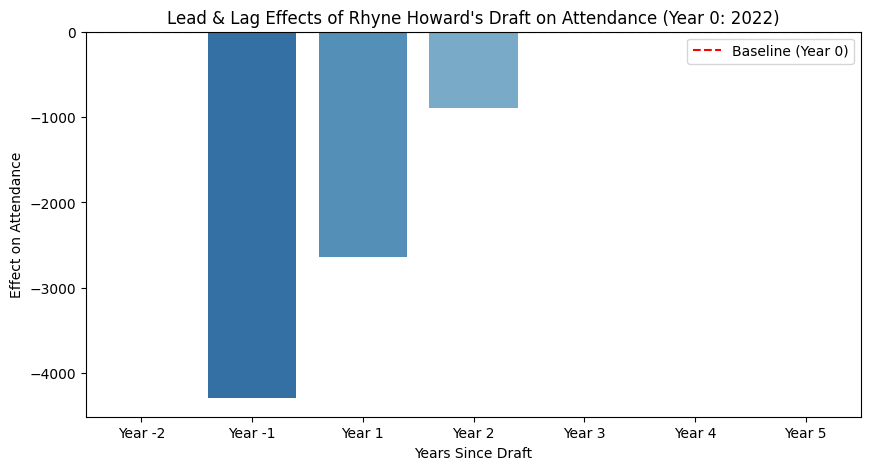

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-5-a0f2f22249b2>:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


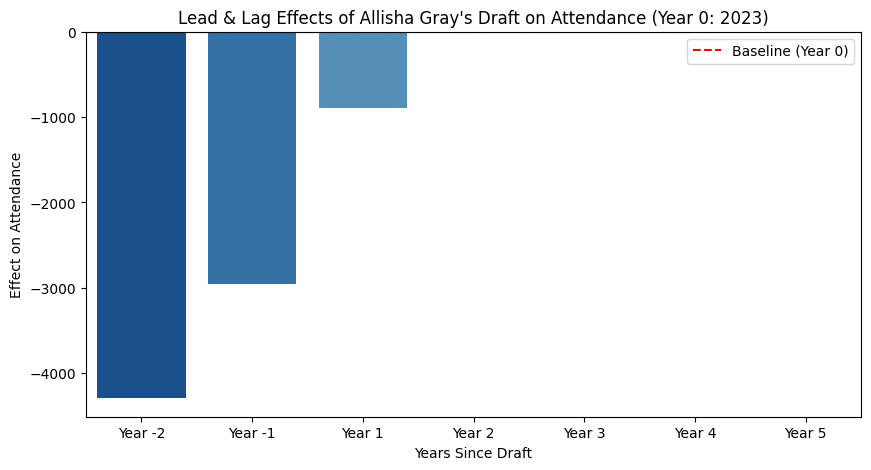

Regression Results for Rhyne Howard (Year Acquired: 2022):
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.216
Model:                            OLS   Adj. R-squared:                  0.207
Method:                 Least Squares   F-statistic:                     26.74
Date:                Wed, 30 Apr 2025   Prob (F-statistic):           2.60e-15
Time:                        04:46:11   Log-Likelihood:                -2694.6
No. Observations:                 296   AIC:                             5397.
Df Residuals:                     292   BIC:                             5412.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

In [5]:
# Atlanta Dream home games
atl_dream_games = attendance_df[attendance_df["Home Team"] == "Atlanta Dream"].copy()

# Define Draft, Trade, and Free Agency Years
draft_trade_free_agency_dates = {
    "Rhyne Howard": pd.Timestamp("2022-04-11"), # drafted
    "Allisha Gray": pd.Timestamp("2023-01-21") # traded
}

# Loop through each drafted player
regression_results = {}
for player, draft_date in draft_trade_free_agency_dates.items():
    # Work on a fresh copy for each player
    player_games = atl_dream_games.copy()

    # Calculate Days Since Draft
    player_games["DaysSinceDraft"] = (player_games["Date"] - draft_date).dt.days

    # Convert Days Since Draft into Years (rounded)
    player_games["YearsSinceDraft"] = player_games["DaysSinceDraft"] // 365

    # Create Lead & Lag Indicator Variables for Years -2 to +5
    for i in range(-2, 6):
        col_name = f"Year_{i}" if i >= 0 else f"Year_m{-i}"
        player_games[col_name] = (player_games["YearsSinceDraft"] == i).astype(int)

    # EXCLUDE Year 0 from the regression (this is the baseline)
    year_vars = [f"Year_{i}" if i >= 1 else f"Year_m{-i}" for i in range(-2, 6) if i != 0]
    formula = "Attendance ~ " + " + ".join(year_vars)

    # Check if any variation exists in independent variables
    if player_games[[col for col in player_games.columns if "Year_" in col]].sum().sum() == 0:
        print(f"Skipping regression for {player} due to no variation in data.")
        continue

    # Run Regression
    model = smf.ols(formula, data=player_games).fit()
    regression_results[player] = model.summary()

    # Extract Effects for Visualization
    effects = model.params.filter(like="Year_")

    # Rename to display more readable labels
    effects.index = effects.index.str.replace("Year_m", "Year -")  # Rename for readability
    effects.index = effects.index.str.replace("Year_", "Year ")  # Clean up the Year_ prefix
    effects = effects.sort_index()

    # Manually reorder the index so that Year -2, Year -1, Year 0, etc., are in the correct order
    correct_order = ["Year -2", "Year -1", "Year 1", "Year 2", "Year 3", "Year 4", "Year 5"]
    effects = effects[correct_order]  # Reorder based on manual sequence

    # Plot Results
    plt.figure(figsize=(10, 5))
    sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")
    plt.axhline(0, linestyle="--", color="red", label="Baseline (Year 0)")
    plt.title(f"Lead & Lag Effects of {player}'s Draft on Attendance (Year 0: {draft_date.year})")
    plt.xlabel("Years Since Draft")
    plt.ylabel("Effect on Attendance")
    plt.legend()
    plt.show()

# Print all regression results
for player, summary in regression_results.items():
    print(f"Regression Results for {player} (Year Acquired: {draft_trade_free_agency_dates[player].year}):")
    print(summary)
    print("\n" + "-"*80 + "\n")

<ipython-input-6-20f7d1eb607e>:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


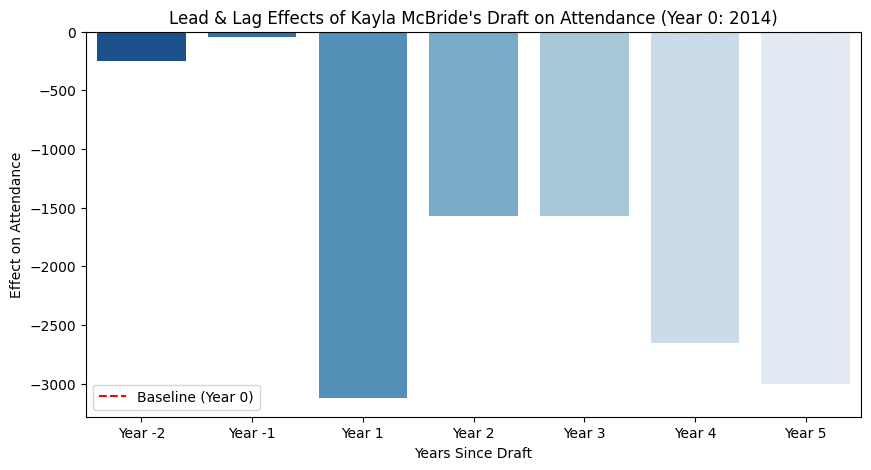

<ipython-input-6-20f7d1eb607e>:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


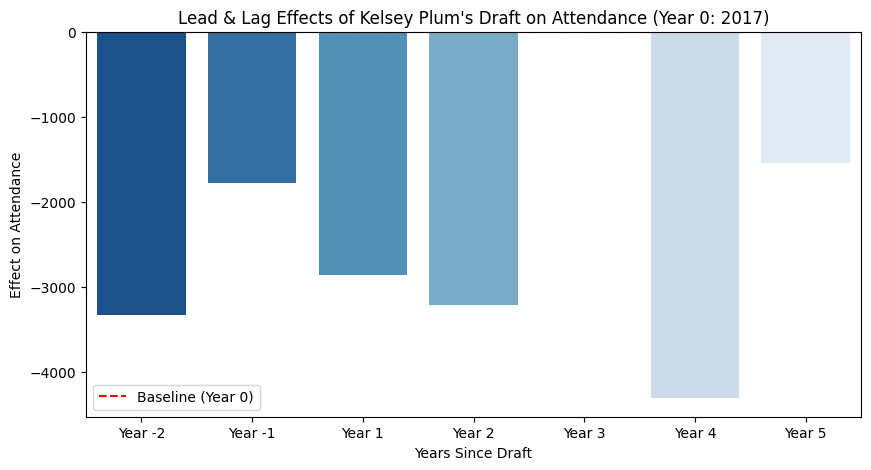

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-6-20f7d1eb607e>:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


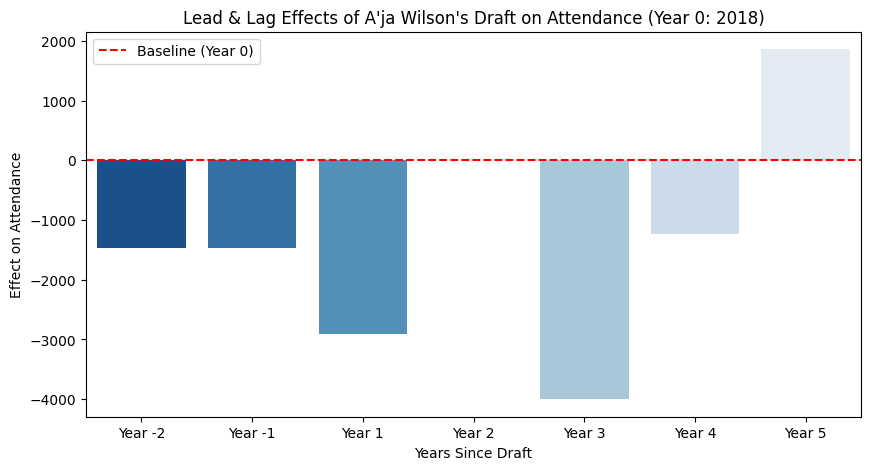

<ipython-input-6-20f7d1eb607e>:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


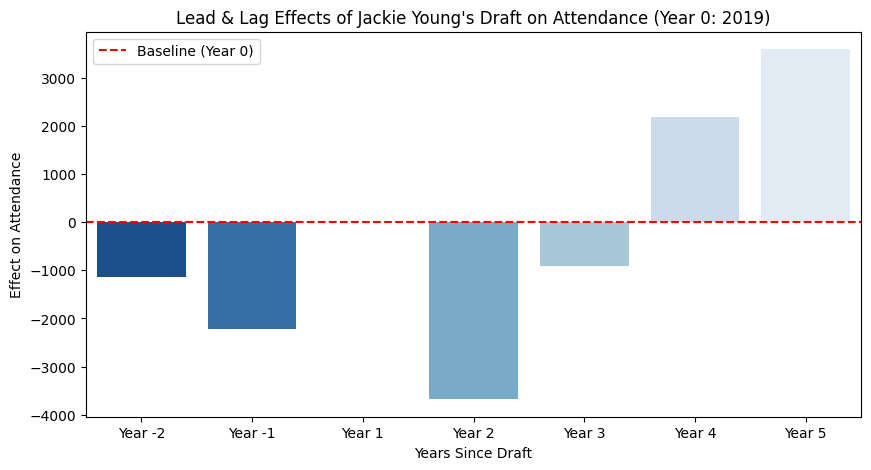

Regression Results for Kayla McBride (Year Acquired: 2014):
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.135
Model:                            OLS   Adj. R-squared:                  0.122
Method:                 Least Squares   F-statistic:                     10.85
Date:                Wed, 30 Apr 2025   Prob (F-statistic):           9.53e-13
Time:                        04:46:12   Log-Likelihood:                -4561.5
No. Observations:                 495   AIC:                             9139.
Df Residuals:                     487   BIC:                             9173.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

In [6]:
# Las Vegas Aces
former_aces = ["Utah Starzz", "San Antonio Silver Stars", "San Antonio Stars", "Las Vegas Aces"]
lv_aces_games = attendance_df[attendance_df["Home Team"].isin(former_aces)].copy()

# Draft Years Dictionary
draft_trade_free_agency_dates = {
    "Kayla McBride": pd.Timestamp("2014-04-14"), # drafted
    "Kelsey Plum": pd.Timestamp("2017-04-13"), # drafted
    "A'ja Wilson": pd.Timestamp("2018-04-12"), # drafted
    "Jackie Young": pd.Timestamp("2019-04-10") # drafted
}

# Loop through each drafted player
regression_results = {}
for player, draft_date in draft_trade_free_agency_dates.items():
    # Work on a fresh copy for each player
    player_games = lv_aces_games.copy()

    # Calculate Days Since Draft
    player_games["DaysSinceDraft"] = (player_games["Date"] - draft_date).dt.days

    # Convert Days Since Draft into Years (rounded)
    player_games["YearsSinceDraft"] = player_games["DaysSinceDraft"] // 365

    # Create Lead & Lag Indicator Variables for Years -2 to +5
    for i in range(-2, 6):
        col_name = f"Year_{i}" if i >= 0 else f"Year_m{-i}"
        player_games[col_name] = (player_games["YearsSinceDraft"] == i).astype(int)

    # EXCLUDE Year 0 from the regression (this is the baseline)
    year_vars = [f"Year_{i}" if i >= 1 else f"Year_m{-i}" for i in range(-2, 6) if i != 0]
    formula = "Attendance ~ " + " + ".join(year_vars)

    # Check if any variation exists in independent variables
    if player_games[[col for col in player_games.columns if "Year_" in col]].sum().sum() == 0:
        print(f"Skipping regression for {player} due to no variation in data.")
        continue

    # Run Regression
    model = smf.ols(formula, data=player_games).fit()
    regression_results[player] = model.summary()

    # Extract Effects for Visualization
    effects = model.params.filter(like="Year_")

    # Rename to display more readable labels
    effects.index = effects.index.str.replace("Year_m", "Year -")  # Rename for readability
    effects.index = effects.index.str.replace("Year_", "Year ")  # Clean up the Year_ prefix
    effects = effects.sort_index()

    # Manually reorder the index so that Year -2, Year -1, Year 0, etc., are in the correct order
    correct_order = ["Year -2", "Year -1", "Year 1", "Year 2", "Year 3", "Year 4", "Year 5"]
    effects = effects[correct_order]  # Reorder based on manual sequence

    # Plot Results
    plt.figure(figsize=(10, 5))
    sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")
    plt.axhline(0, linestyle="--", color="red", label="Baseline (Year 0)")
    plt.title(f"Lead & Lag Effects of {player}'s Draft on Attendance (Year 0: {draft_date.year})")
    plt.xlabel("Years Since Draft")
    plt.ylabel("Effect on Attendance")
    plt.legend()
    plt.show()

# Print all regression results
for player, summary in regression_results.items():
    print(f"Regression Results for {player} (Year Acquired: {draft_trade_free_agency_dates[player].year}):")
    print(summary)
    print("\n" + "-"*80 + "\n")


/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-7-21be610ff495>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


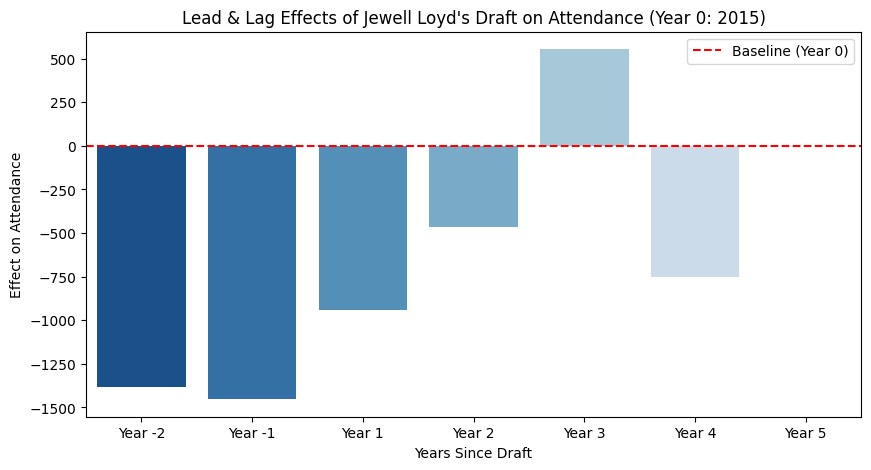

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-7-21be610ff495>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


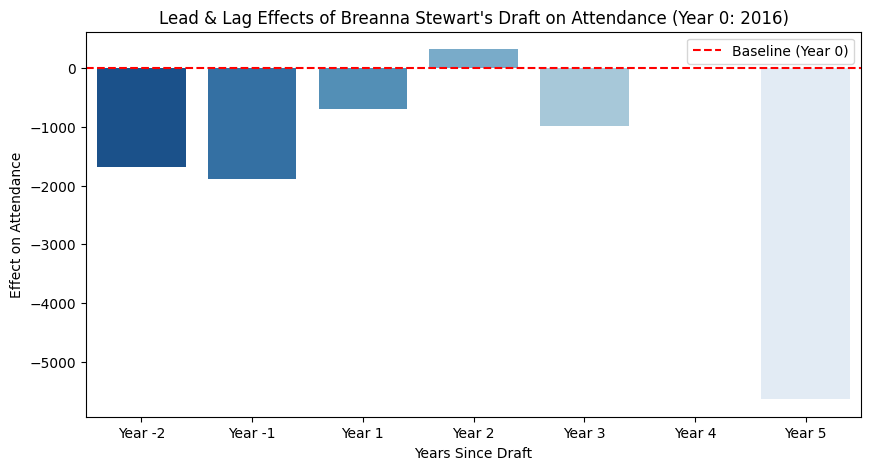

<ipython-input-7-21be610ff495>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


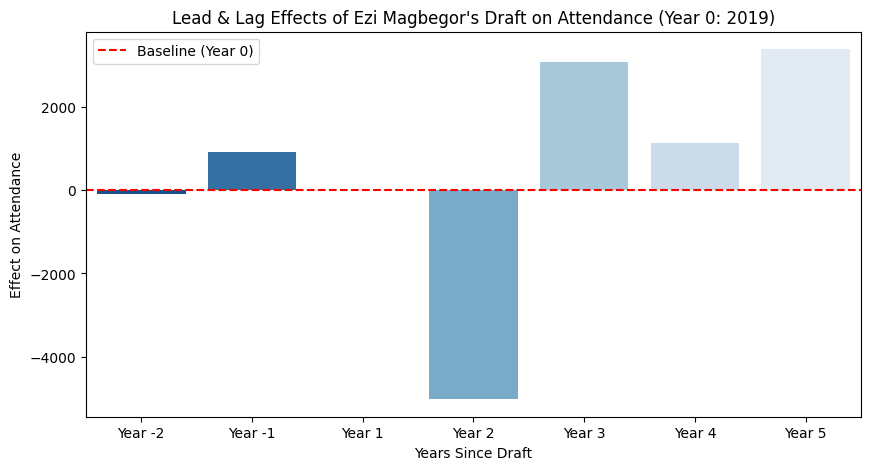

Regression Results for Jewell Loyd (Year Acquired: 2015):
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.032
Model:                            OLS   Adj. R-squared:                  0.019
Method:                 Least Squares   F-statistic:                     2.441
Date:                Wed, 30 Apr 2025   Prob (F-statistic):             0.0248
Time:                        04:46:13   Log-Likelihood:                -4104.6
No. Observations:                 444   AIC:                             8223.
Df Residuals:                     437   BIC:                             8252.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------

In [7]:
# Seattle Storm home games
sea_storm_games = attendance_df[attendance_df["Home Team"] == "Seattle Storm"].copy()

# Define WNBA Draft, Trade, and Free Agency Years
draft_trade_free_agency_dates = {
    "Jewell Loyd": pd.Timestamp("2015-04-16"), # drafted
    "Breanna Stewart": pd.Timestamp("2016-04-14"), # drafted
    "Ezi Magbegor": pd.Timestamp("2019-04-10") # drafted
}

# Loop through each drafted player
regression_results = {}
for player, draft_date in draft_trade_free_agency_dates.items():
    # Work on a fresh copy for each player
    player_games = sea_storm_games.copy()

    # Calculate Days Since Draft
    player_games["DaysSinceDraft"] = (player_games["Date"] - draft_date).dt.days

    # Convert Days Since Draft into Years (rounded)
    player_games["YearsSinceDraft"] = player_games["DaysSinceDraft"] // 365

    # Create Lead & Lag Indicator Variables for Years -2 to +5
    for i in range(-2, 6):
        col_name = f"Year_{i}" if i >= 0 else f"Year_m{-i}"
        player_games[col_name] = (player_games["YearsSinceDraft"] == i).astype(int)

    # EXCLUDE Year 0 from the regression (this is the baseline)
    year_vars = [f"Year_{i}" if i >= 1 else f"Year_m{-i}" for i in range(-2, 6) if i != 0]
    formula = "Attendance ~ " + " + ".join(year_vars)

    # Check if any variation exists in independent variables
    if player_games[[col for col in player_games.columns if "Year_" in col]].sum().sum() == 0:
        print(f"Skipping regression for {player} due to no variation in data.")
        continue

    # Run Regression
    model = smf.ols(formula, data=player_games).fit()
    regression_results[player] = model.summary()

    # Extract Effects for Visualization
    effects = model.params.filter(like="Year_")

    # Rename to display more readable labels
    effects.index = effects.index.str.replace("Year_m", "Year -")  # Rename for readability
    effects.index = effects.index.str.replace("Year_", "Year ")  # Clean up the Year_ prefix
    effects = effects.sort_index()

    # Manually reorder the index so that Year -2, Year -1, Year 0, etc., are in the correct order
    correct_order = ["Year -2", "Year -1", "Year 1", "Year 2", "Year 3", "Year 4", "Year 5"]
    effects = effects[correct_order]  # Reorder based on manual sequence

    # Plot Results
    plt.figure(figsize=(10, 5))
    sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")
    plt.axhline(0, linestyle="--", color="red", label="Baseline (Year 0)")
    plt.title(f"Lead & Lag Effects of {player}'s Draft on Attendance (Year 0: {draft_date.year})")
    plt.xlabel("Years Since Draft")
    plt.ylabel("Effect on Attendance")
    plt.legend()
    plt.show()

# Print all regression results
for player, summary in regression_results.items():
    print(f"Regression Results for {player} (Year Acquired: {draft_trade_free_agency_dates[player].year}):")
    print(summary)
    print("\n" + "-"*80 + "\n")


<ipython-input-8-746f0c4f93b3>:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


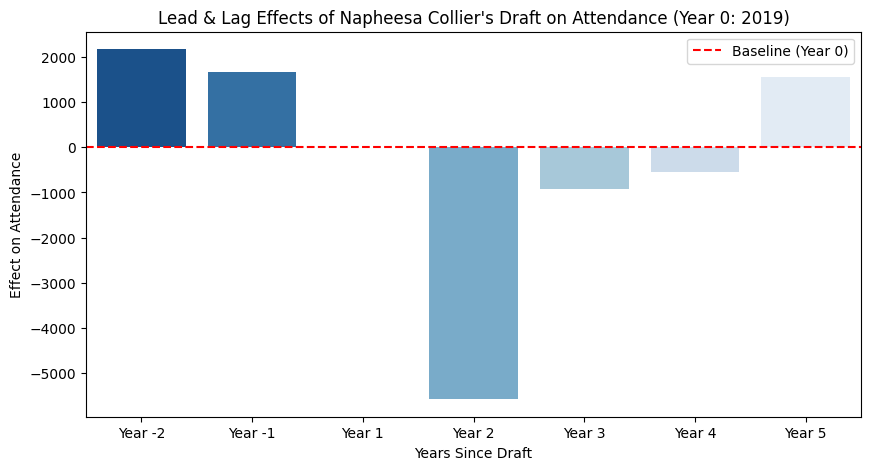

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-8-746f0c4f93b3>:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


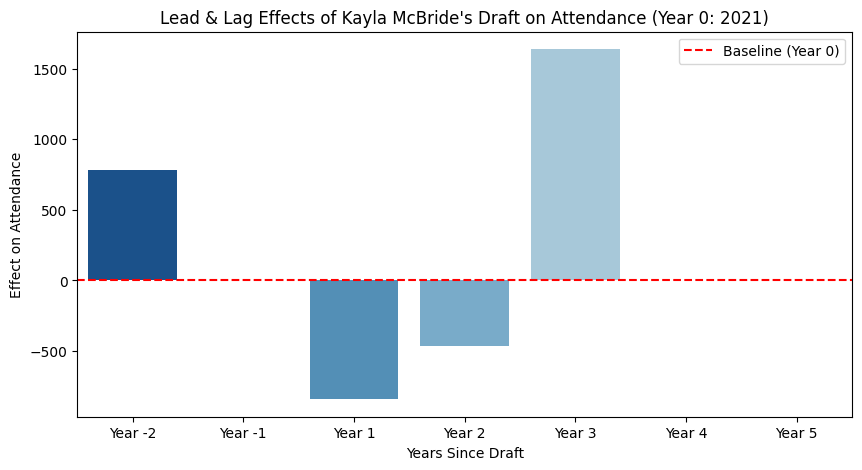

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-8-746f0c4f93b3>:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


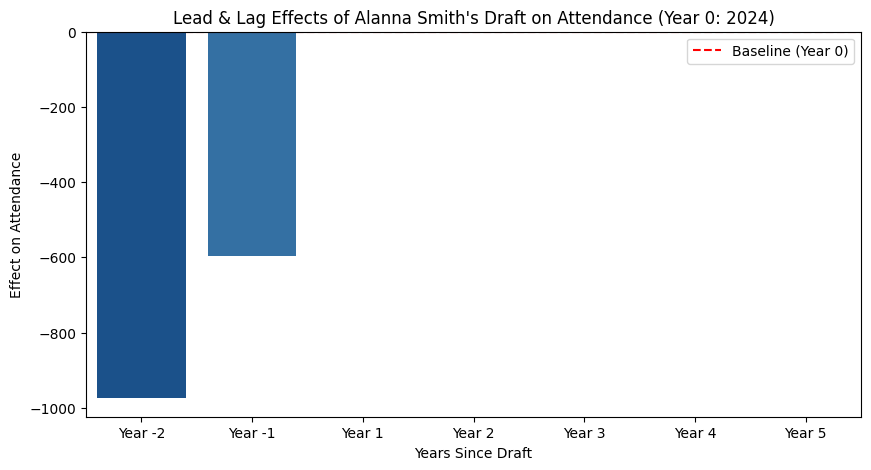

Regression Results for Napheesa Collier (Year Acquired: 2019):
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.196
Model:                            OLS   Adj. R-squared:                  0.186
Method:                 Least Squares   F-statistic:                     18.87
Date:                Wed, 30 Apr 2025   Prob (F-statistic):           1.10e-19
Time:                        04:46:13   Log-Likelihood:                -4359.2
No. Observations:                 470   AIC:                             8732.
Df Residuals:                     463   BIC:                             8761.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

In [8]:
# Minnesota Lynx home games
min_lynx_games = attendance_df[attendance_df["Home Team"] == "Minnesota Lynx"].copy()

# Define WNBA Draft, Trade, and Free Agency Years
draft_trade_free_agency_dates = {
    "Napheesa Collier": pd.Timestamp("2019-04-10"), # drafted
    "Kayla McBride": pd.Timestamp("2021-02-01"), # free agency
    "Alanna Smith": pd.Timestamp("2024-02-01") # free agency

}

# Loop through each drafted player
regression_results = {}
for player, draft_date in draft_trade_free_agency_dates.items():
    # Work on a fresh copy for each player
    player_games = min_lynx_games.copy()

    # Calculate Days Since Draft
    player_games["DaysSinceDraft"] = (player_games["Date"] - draft_date).dt.days

    # Convert Days Since Draft into Years (rounded)
    player_games["YearsSinceDraft"] = player_games["DaysSinceDraft"] // 365

    # Create Lead & Lag Indicator Variables for Years -2 to +5
    for i in range(-2, 6):
        col_name = f"Year_{i}" if i >= 0 else f"Year_m{-i}"
        player_games[col_name] = (player_games["YearsSinceDraft"] == i).astype(int)

    # EXCLUDE Year 0 from the regression (this is the baseline)
    year_vars = [f"Year_{i}" if i >= 1 else f"Year_m{-i}" for i in range(-2, 6) if i != 0]
    formula = "Attendance ~ " + " + ".join(year_vars)

    # Check if any variation exists in independent variables
    if player_games[[col for col in player_games.columns if "Year_" in col]].sum().sum() == 0:
        print(f"Skipping regression for {player} due to no variation in data.")
        continue

    # Run Regression
    model = smf.ols(formula, data=player_games).fit()
    regression_results[player] = model.summary()

    # Extract Effects for Visualization
    effects = model.params.filter(like="Year_")

    # Rename to display more readable labels
    effects.index = effects.index.str.replace("Year_m", "Year -")  # Rename for readability
    effects.index = effects.index.str.replace("Year_", "Year ")  # Clean up the Year_ prefix
    effects = effects.sort_index()

    # Manually reorder the index so that Year -2, Year -1, Year 0, etc., are in the correct order
    correct_order = ["Year -2", "Year -1", "Year 1", "Year 2", "Year 3", "Year 4", "Year 5"]
    effects = effects[correct_order]  # Reorder based on manual sequence

    # Plot Results
    plt.figure(figsize=(10, 5))
    sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")
    plt.axhline(0, linestyle="--", color="red", label="Baseline (Year 0)")
    plt.title(f"Lead & Lag Effects of {player}'s Draft on Attendance (Year 0: {draft_date.year})")
    plt.xlabel("Years Since Draft")
    plt.ylabel("Effect on Attendance")
    plt.legend()
    plt.show()

# Print all regression results
for player, summary in regression_results.items():
    print(f"Regression Results for {player} (Year Acquired: {draft_trade_free_agency_dates[player].year}):")
    print(summary)
    print("\n" + "-"*80 + "\n")


<ipython-input-9-e6eeba777a12>:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


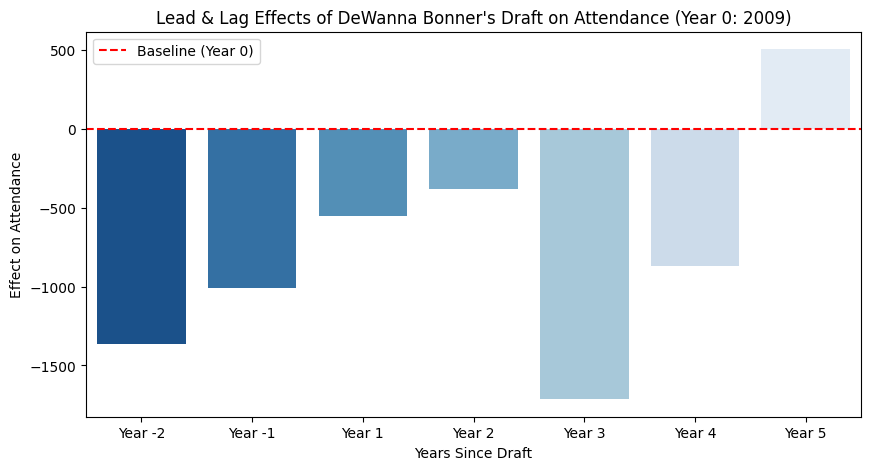

<ipython-input-9-e6eeba777a12>:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


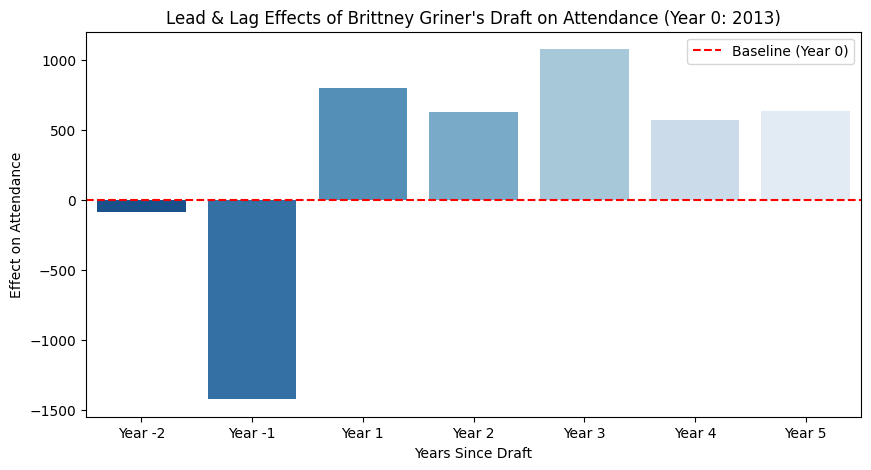

<ipython-input-9-e6eeba777a12>:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


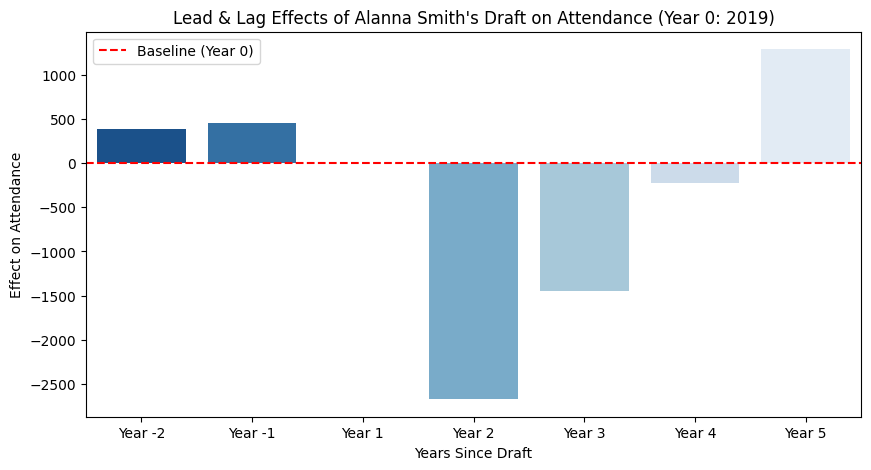

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-9-e6eeba777a12>:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


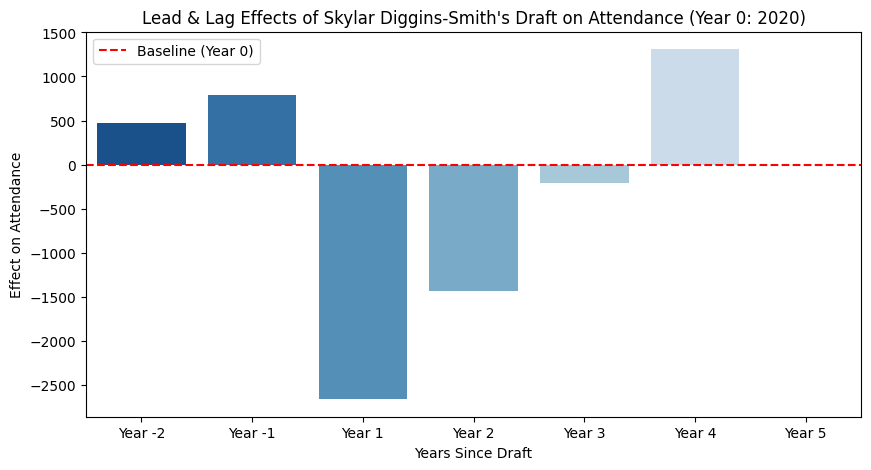

Regression Results for DeWanna Bonner (Year Acquired: 2009):
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.035
Model:                            OLS   Adj. R-squared:                  0.022
Method:                 Least Squares   F-statistic:                     2.558
Date:                Wed, 30 Apr 2025   Prob (F-statistic):             0.0135
Time:                        04:46:14   Log-Likelihood:                -4578.7
No. Observations:                 495   AIC:                             9173.
Df Residuals:                     487   BIC:                             9207.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------

In [9]:
# Phoenix Mercury home games
phx_mercury_games = attendance_df[attendance_df["Home Team"] == "Phoenix Mercury"].copy()

# Define WNBA Draft, Trade, and Free Agency Years (Adjust if needed)
draft_trade_free_agency_dates = {
    "DeWanna Bonner": pd.Timestamp("2009-04-09"), # drafted
    "Brittney Griner": pd.Timestamp("2013-04-15"), # drafted
    "Alanna Smith": pd.Timestamp("2019-04-10"), # drafted
    "Skylar Diggins-Smith": pd.Timestamp("2020-02-12") # traded
}

# Loop through each drafted player
regression_results = {}
for player, draft_date in draft_trade_free_agency_dates.items():
    # Work on a fresh copy for each player
    player_games = phx_mercury_games.copy()

    # Calculate Days Since Draft
    player_games["DaysSinceDraft"] = (player_games["Date"] - draft_date).dt.days

    # Convert Days Since Draft into Years (rounded)
    player_games["YearsSinceDraft"] = player_games["DaysSinceDraft"] // 365

    # Create Lead & Lag Indicator Variables for Years -2 to +5
    for i in range(-2, 6):
        col_name = f"Year_{i}" if i >= 0 else f"Year_m{-i}"
        player_games[col_name] = (player_games["YearsSinceDraft"] == i).astype(int)

    # EXCLUDE Year 0 from the regression (this is the baseline)
    year_vars = [f"Year_{i}" if i >= 1 else f"Year_m{-i}" for i in range(-2, 6) if i != 0]
    formula = "Attendance ~ " + " + ".join(year_vars)

    # Check if any variation exists in independent variables
    if player_games[[col for col in player_games.columns if "Year_" in col]].sum().sum() == 0:
        print(f"Skipping regression for {player} due to no variation in data.")
        continue

    # Run Regression
    model = smf.ols(formula, data=player_games).fit()
    regression_results[player] = model.summary()

    # Extract Effects for Visualization
    effects = model.params.filter(like="Year_")

    # Rename to display more readable labels
    effects.index = effects.index.str.replace("Year_m", "Year -")  # Rename for readability
    effects.index = effects.index.str.replace("Year_", "Year ")  # Clean up the Year_ prefix
    effects = effects.sort_index()

    # Manually reorder the index so that Year -2, Year -1, Year 0, etc., are in the correct order
    correct_order = ["Year -2", "Year -1", "Year 1", "Year 2", "Year 3", "Year 4", "Year 5"]
    effects = effects[correct_order]  # Reorder based on manual sequence

    # Plot Results
    plt.figure(figsize=(10, 5))
    sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")
    plt.axhline(0, linestyle="--", color="red", label="Baseline (Year 0)")
    plt.title(f"Lead & Lag Effects of {player}'s Draft on Attendance (Year 0: {draft_date.year})")
    plt.xlabel("Years Since Draft")
    plt.ylabel("Effect on Attendance")
    plt.legend()
    plt.show()

# Print all regression results
for player, summary in regression_results.items():
    print(f"Regression Results for {player} (Year Acquired: {draft_trade_free_agency_dates[player].year}):")
    print(summary)
    print("\n" + "-"*80 + "\n")


<ipython-input-10-bb1eec0fb348>:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


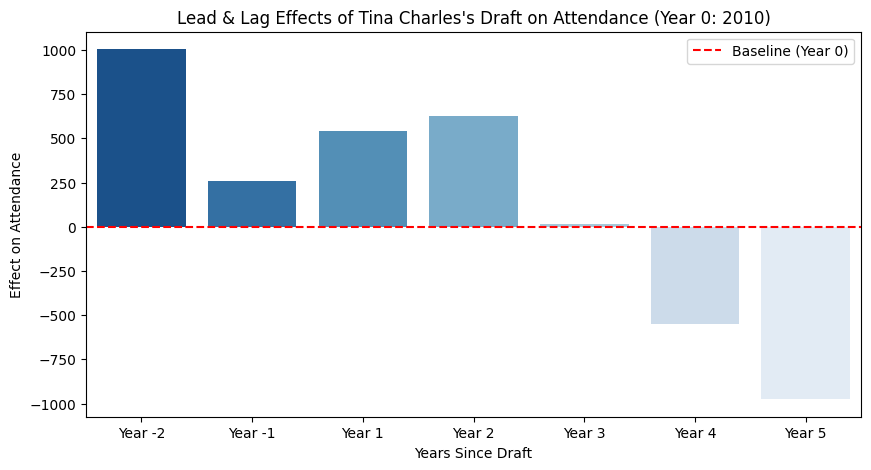

<ipython-input-10-bb1eec0fb348>:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


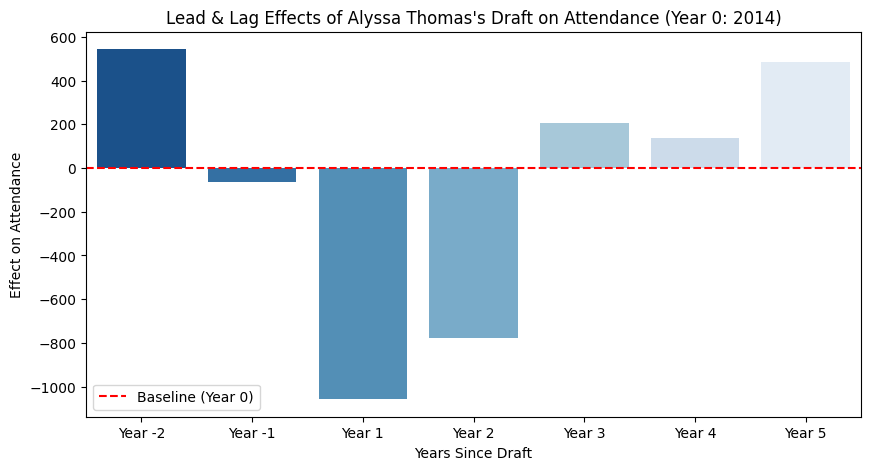

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-10-bb1eec0fb348>:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


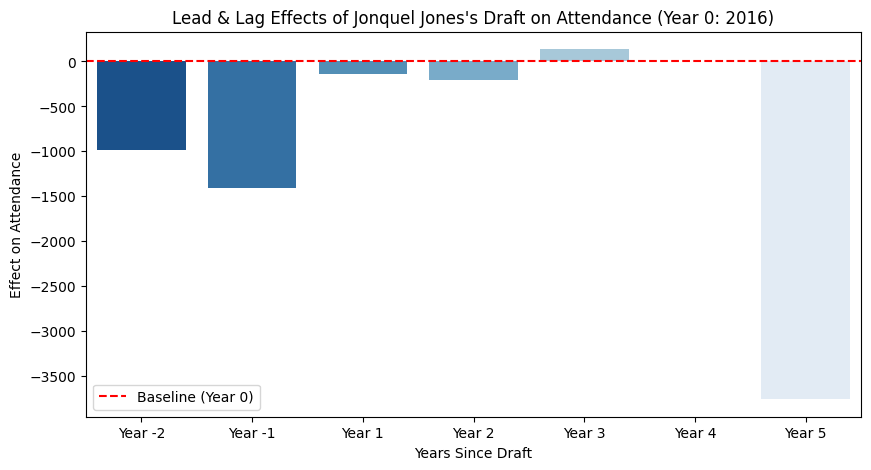

<ipython-input-10-bb1eec0fb348>:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


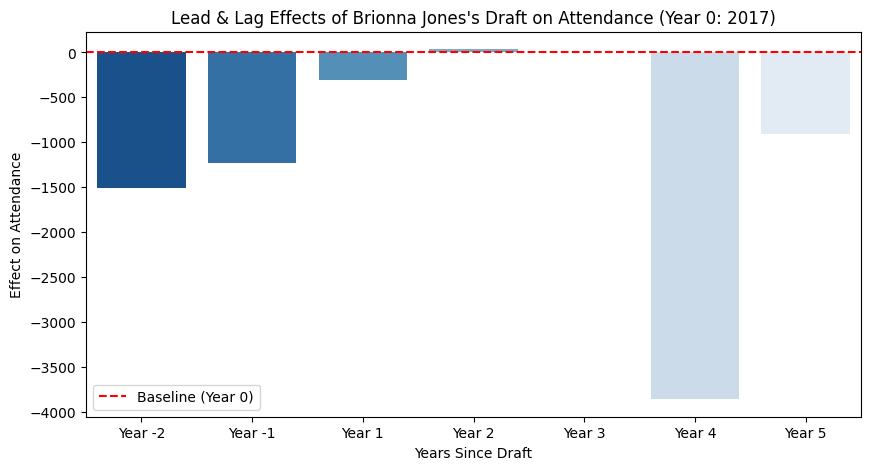

/usr/local/lib/python3.11/dist-packages/statsmodels/regression/linear_model.py:1966: RuntimeWarning: divide by zero encountered in scalar divide
  return np.sqrt(eigvals[0]/eigvals[-1])
<ipython-input-10-bb1eec0fb348>:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


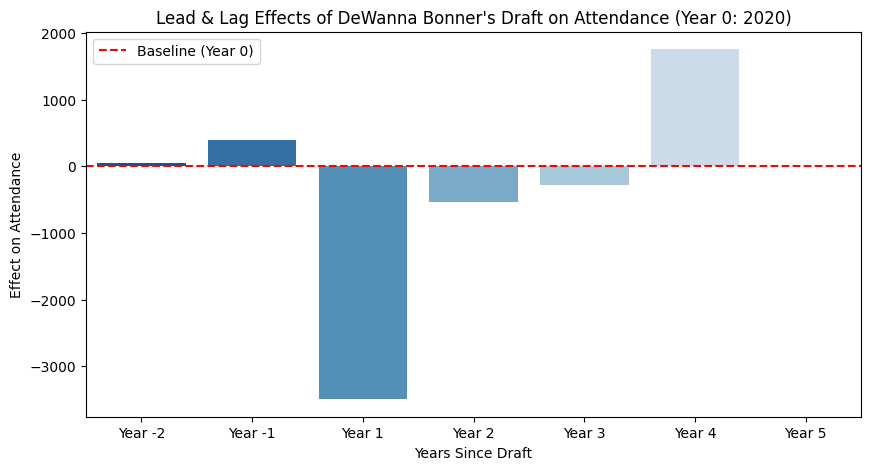

Regression Results for Tina Charles (Year Acquired: 2010):
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.060
Model:                            OLS   Adj. R-squared:                  0.038
Method:                 Least Squares   F-statistic:                     2.721
Date:                Wed, 30 Apr 2025   Prob (F-statistic):            0.00947
Time:                        04:46:15   Log-Likelihood:                -2701.8
No. Observations:                 306   AIC:                             5420.
Df Residuals:                     298   BIC:                             5449.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------

In [10]:
# Connecticut Sun home games
con_sun_games = attendance_df[attendance_df["Home Team"] == "Connecticut Sun"].copy()

# Define WNBA Draft, Trade, and Free Agency Years (Adjust if needed)
draft_trade_free_agency_dates = {
    "Tina Charles": pd.Timestamp("2010-04-08"), # drafted
    "Alyssa Thomas": pd.Timestamp("2014-04-12"), # traded
    "Jonquel Jones": pd.Timestamp("2016-04-14"), # traded
    "Brionna Jones": pd.Timestamp("2017-04-13"), # drafted
    "DeWanna Bonner": pd.Timestamp("2020-02-11") # traded
}

# Ensure relevant years are included (at least 2 years before draft)
con_sun_games = con_sun_games[con_sun_games["Year"] >= 2008]

# Loop through each drafted player
regression_results = {}
for player, draft_date in draft_trade_free_agency_dates.items():
    # Work on a fresh copy for each player
    player_games = con_sun_games.copy()

    # Calculate Days Since Draft
    player_games["DaysSinceDraft"] = (player_games["Date"] - draft_date).dt.days

    # Convert Days Since Draft into Years (rounded)
    player_games["YearsSinceDraft"] = player_games["DaysSinceDraft"] // 365

    # Create Lead & Lag Indicator Variables for Years -2 to +5
    for i in range(-2, 6):
        col_name = f"Year_{i}" if i >= 0 else f"Year_m{-i}"
        player_games[col_name] = (player_games["YearsSinceDraft"] == i).astype(int)

    # EXCLUDE Year 0 from the regression (this is the baseline)
    year_vars = [f"Year_{i}" if i >= 1 else f"Year_m{-i}" for i in range(-2, 6) if i != 0]
    formula = "Attendance ~ " + " + ".join(year_vars)

    # Check if any variation exists in independent variables
    if player_games[[col for col in player_games.columns if "Year_" in col]].sum().sum() == 0:
        print(f"Skipping regression for {player} due to no variation in data.")
        continue

    # Run Regression
    model = smf.ols(formula, data=player_games).fit()
    regression_results[player] = model.summary()

    # Extract Effects for Visualization
    effects = model.params.filter(like="Year_")

    # Rename to display more readable labels
    effects.index = effects.index.str.replace("Year_m", "Year -")  # Rename for readability
    effects.index = effects.index.str.replace("Year_", "Year ")  # Clean up the Year_ prefix
    effects = effects.sort_index()

    # Manually reorder the index so that Year -2, Year -1, Year 0, etc., are in the correct order
    correct_order = ["Year -2", "Year -1", "Year 1", "Year 2", "Year 3", "Year 4", "Year 5"]
    effects = effects[correct_order]  # Reorder based on manual sequence

    # Plot Results
    plt.figure(figsize=(10, 5))
    sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")
    plt.axhline(0, linestyle="--", color="red", label="Baseline (Year 0)")
    plt.title(f"Lead & Lag Effects of {player}'s Draft on Attendance (Year 0: {draft_date.year})")
    plt.xlabel("Years Since Draft")
    plt.ylabel("Effect on Attendance")
    plt.legend()
    plt.show()

# Print all regression results
for player, summary in regression_results.items():
    print(f"Regression Results for {player} (Year Acquired: {draft_trade_free_agency_dates[player].year}):")
    print(summary)
    print("\n" + "-"*80 + "\n")


<ipython-input-11-140d8caeecfe>:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


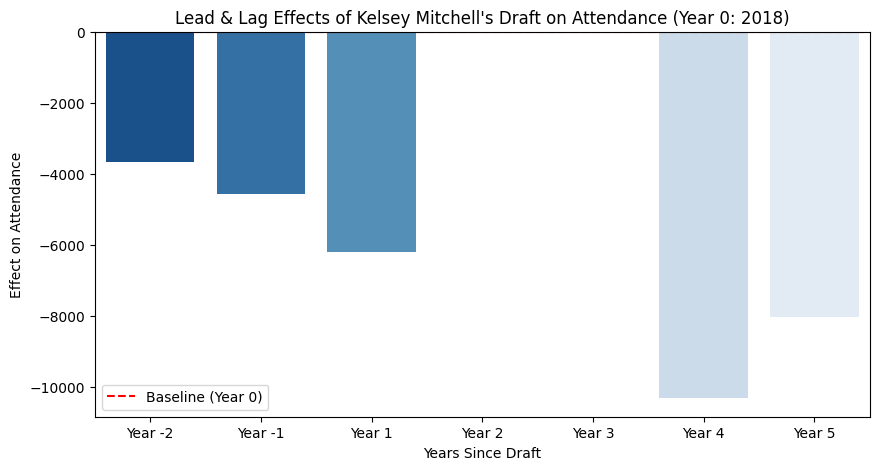

Regression Results for Kelsey Mitchell (Year Acquired: 2018):
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.552
Model:                            OLS   Adj. R-squared:                  0.534
Method:                 Least Squares   F-statistic:                     29.87
Date:                Wed, 30 Apr 2025   Prob (F-statistic):           1.16e-19
Time:                        04:46:17   Log-Likelihood:                -1207.8
No. Observations:                 127   AIC:                             2428.
Df Residuals:                     121   BIC:                             2445.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------

In [11]:
# Indiana Fever home games
ind_fever_games = attendance_df[attendance_df["Home Team"] == "Indiana Fever"].copy()

# Define Exact Draft Date
draft_trade_free_agency_dates = {
    "Kelsey Mitchell": pd.Timestamp("2018-04-12"), # drafted
}

# Ensure relevant years are included (at least 2 years before draft)
ind_fever_games = ind_fever_games[ind_fever_games["Year"] >= 2016]

# Loop through each drafted player
regression_results = {}
for player, draft_date in draft_trade_free_agency_dates.items():
    # Work on a fresh copy for each player
    player_games = ind_fever_games.copy()

    # Calculate Days Since Draft
    player_games["DaysSinceDraft"] = (player_games["Date"] - draft_date).dt.days

    # Convert Days Since Draft into Years (rounded)
    player_games["YearsSinceDraft"] = player_games["DaysSinceDraft"] // 365

    # Create Lead & Lag Indicator Variables for Years -2 to +5
    for i in range(-2, 6):
        col_name = f"Year_{i}" if i >= 0 else f"Year_m{-i}"
        player_games[col_name] = (player_games["YearsSinceDraft"] == i).astype(int)

    # EXCLUDE Year 0 from the regression (this is the baseline)
    year_vars = [f"Year_{i}" if i >= 1 else f"Year_m{-i}" for i in range(-2, 6) if i != 0]
    formula = "Attendance ~ " + " + ".join(year_vars)

    # Check if any variation exists in independent variables
    if player_games[[col for col in player_games.columns if "Year_" in col]].sum().sum() == 0:
        print(f"Skipping regression for {player} due to no variation in data.")
        continue

    # Run Regression
    model = smf.ols(formula, data=player_games).fit()
    regression_results[player] = model.summary()

    # Extract Effects for Visualization
    effects = model.params.filter(like="Year_")

    # Rename to display more readable labels
    effects.index = effects.index.str.replace("Year_m", "Year -")  # Rename for readability
    effects.index = effects.index.str.replace("Year_", "Year ")  # Clean up the Year_ prefix
    effects = effects.sort_index()

    # Manually reorder the index so that Year -2, Year -1, Year 0, etc., are in the correct order
    correct_order = ["Year -2", "Year -1", "Year 1", "Year 2", "Year 3", "Year 4", "Year 5"]
    effects = effects[correct_order]  # Reorder based on manual sequence

    # Plot Results
    plt.figure(figsize=(10, 5))
    sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")
    plt.axhline(0, linestyle="--", color="red", label="Baseline (Year 0)")
    plt.title(f"Lead & Lag Effects of {player}'s Draft on Attendance (Year 0: {draft_date.year})")
    plt.xlabel("Years Since Draft")
    plt.ylabel("Effect on Attendance")
    plt.legend()
    plt.show()

# Print all regression results
for player, summary in regression_results.items():
    print(f"Regression Results for {player} (Year Acquired: {draft_trade_free_agency_dates[player].year}):")
    print(summary)
    print("\n" + "-"*80 + "\n")


In [12]:
# Create a table from the actual regression results provided by the user

actual_regression_results = pd.DataFrame({
    "Year": ["Year -2", "Year -1", "Year 1", "Year 2", "Year 3", "Year 4", "Year 5"],
    "Coefficient": [-3660.99, -4570.67, -6221.44, -0.00, 0.00, -10330.00, -8041.58],
    "Standard Error": [961.25, 980.09, 980.09, 6.24e-12, 0.00, 961.25, 928.35],
    "t-Value": [-3.81, -4.66, -6.35, -4.69, float('nan'), -10.75, -8.66],
    "p-Value": [0.000, 0.000, 0.000, 0.000, float('nan'), 0.000, 0.000]
})

actual_regression_results

,Year,Coefficient,Standard Error,t-Value,p-Value
0,Year -2,-3660.99,9.612500e+02,-3.81,0.0
1,Year -1,-4570.67,9.800900e+02,-4.66,0.0
2,Year 1,-6221.44,9.800900e+02,-6.35,0.0
3,Year 2,-0.00,6.240000e-12,-4.69,0.0
4,Year 3,0.00,0.000000e+00,NaN,NaN
5,Year 4,-10330.00,9.612500e+02,-10.75,0.0
6,Year 5,-8041.58,9.283500e+02,-8.66,0.0


<ipython-input-13-d8898554a7aa>:54: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")


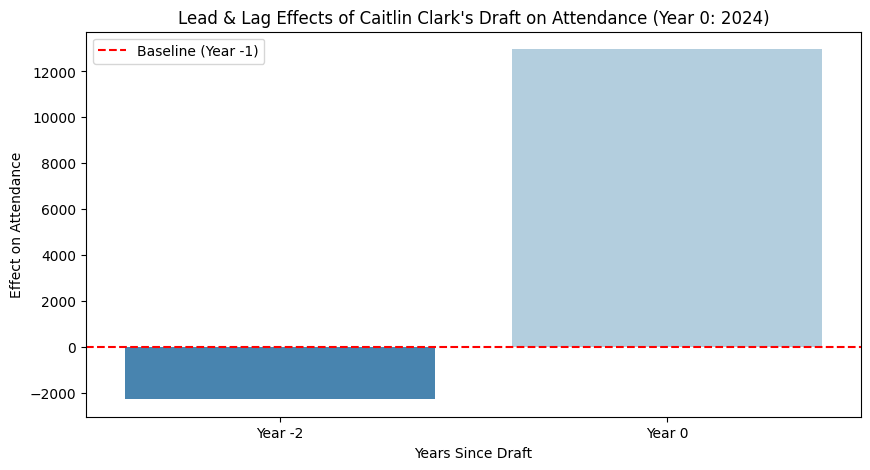

Regression Results for Caitlin Clark (Year Acquired: 2024):
                            OLS Regression Results                            
Dep. Variable:             Attendance   R-squared:                       0.982
Model:                            OLS   Adj. R-squared:                  0.982
Method:                 Least Squares   F-statistic:                     1537.
Date:                Wed, 30 Apr 2025   Prob (F-statistic):           5.43e-49
Time:                        04:46:17   Log-Likelihood:                -476.97
No. Observations:                  58   AIC:                             959.9
Df Residuals:                      55   BIC:                             966.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

In [13]:
# Caitlin Clark (drafted in 2024)
# Indiana Fever home games
ind_fever_games = attendance_df[attendance_df["Home Team"] == "Indiana Fever"].copy()

# Define Exact Draft Date
draft_trade_free_agency_dates = {
    "Caitlin Clark" : pd.Timestamp("2024-04-15") # drafted
}

# Ensure relevant years are included (at least 2 years before draft)
ind_fever_games = ind_fever_games[ind_fever_games["Year"] >= 2022]

# Loop through each drafted player
regression_results = {}
for player, draft_date in draft_trade_free_agency_dates.items():
    # Work on a fresh copy for each player
    player_games = ind_fever_games.copy()

    # Calculate Days Since Draft
    player_games["DaysSinceDraft"] = (player_games["Date"] - draft_date).dt.days

    # Convert Days Since Draft into Years (rounded)
    player_games["YearsSinceDraft"] = player_games["DaysSinceDraft"] // 365

    # Create Lead & Lag Indicator Variables for Years -2 to +5
    for i in range(-2, 6):
        column_name = f"Year_{i}" if i >= 0 else f"Year_m{-i}"  # Rename negatives
        player_games[column_name] = (player_games["YearsSinceDraft"] == i).astype(int)

    # Define Regression Formula
    # Include Year_0 in regression and exclude Year_m1
    year_vars = [f"Year_m2", f"Year_0"]  # Compare Year 0 to prior years
    formula = "Attendance ~ Year_m2 + Year_0"

    # Check if any variation exists in independent variables
    if player_games[[col for col in player_games.columns if "Year_" in col]].sum().sum() == 0:
        print(f"Skipping regression for {player} due to no variation in data.")
        continue

    # Run Regression
    model = smf.ols(formula, data=player_games).fit()
    regression_results[player] = model.summary()

    # Extract Effects for Visualization
    effects = model.params.filter(like="Year_")

    # Rename to display more readable labels
    effects.index = effects.index.str.replace("Year_m", "Year -")  # Rename for readability
    effects.index = effects.index.str.replace("Year_", "Year ")  # Clean up the Year_ prefix
    effects = effects.sort_index()

    # Plot Results
    plt.figure(figsize=(10, 5))
    sns.barplot(x=effects.index, y=effects.values, palette="Blues_r")
    plt.axhline(0, linestyle="--", color="red", label="Baseline (Year -1)")
    plt.title(f"Lead & Lag Effects of {player}'s Draft on Attendance (Year 0: {draft_date.year})")
    plt.xlabel("Years Since Draft")
    plt.ylabel("Effect on Attendance")
    plt.legend()
    plt.show()

# Print all regression results
for player, summary in regression_results.items():
    print(f"Regression Results for {player} (Year Acquired: {draft_trade_free_agency_dates[player].year}):")
    print(summary)
    print("\n" + "-"*80 + "\n")


In [14]:
# Create a table from the actual regression results provided by the user for Caitlin Clark

caitlin_clark_actual_results = pd.DataFrame({
    "Year": ["Year -2", "Year 0"],
    "Coefficient": [-2291.02, 12970.00],
    "Standard Error": [300.95, 292.92],
    "t-Value": [-7.61, 44.28],
    "p-Value": [0.000, 0.000]
})

caitlin_clark_actual_results

,Year,Coefficient,Standard Error,t-Value,p-Value
0,Year -2,-2291.02,300.95,-7.61,0.0
1,Year 0,12970.00,292.92,44.28,0.0
